In [1]:
import pandas as pd

df = pd.read_csv('data.csv')

In [2]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


### lowercase and replace spaces with underscores.
We can also chain multiple string commands. The other one we want is replace, to replace spaces with underscores:

In [3]:
df.columns.str.lower().str.replace(' ', '_')

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'msrp'],
      dtype='str')

This alone changes nothing — we need to write the result back to the columns attribute:

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


Now the column names are uniform: all lowercase, no spaces. Cleaner.

### Finding the string columns

The values have the same problem: sometimes they are all caps 
(BMW, MANUAL), sometimes not. Let's normalize the string values the same way.

First we need to find out which columns are strings — we cannot apply string methods to numbers. For that we use the dtypes attribute. It tells us, for every column, what type it is:

In [6]:
df.dtypes


make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

The type we are interested in is object — in pandas, that is how strings are stored.

It can technically be other objects, but when we read data from a CSV file, an object column is nothing else but strings.

To select only the columns of type object, we compare dtypes with 'object'. 

This gives us a series where the values are the types and the index contains the column names:

In [7]:
#for this example, no objects found, so I filtered using the str.
df.dtypes[df.dtypes == 'str']

make                 str
model                str
engine_fuel_type     str
transmission_type    str
driven_wheels        str
market_category      str
vehicle_size         str
vehicle_style        str
dtype: object

The values are all "object" — we are not interested in them. 

What we want are the names, so we take the index of this series and convert it to a Python list. 

No particular reason, it just looks nicer:

In [8]:
strings = list(df.dtypes[df.dtypes == 'str'].index)
strings

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

### Normalizing the string values

Now that we have all the string column names, 

we loop over them and apply the same transformation we used for the column names: 

lowercase everything and replace spaces with underscores, writing the result back to the DataFrame:

In [9]:
for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [10]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


# Exploratory data analysis

previously, we prepared the columns of our DataFrame. 

Now we do exploratory data analysis (EDA): we look at every column, 

see what kind of values are there, a

nd try to get a feeling for the data and the problem before training a model.

## Looking at every column

We already know that some columns are strings and some are numbers. 

To see what is inside each of them, we iterate over all columns and print some statistics for every one: 

the column name, a few values, and the number of unique values:

In [11]:
for col in df.columns:
    print(col)
    print("Unique, the first 5", df[col].unique()[:5])
    print("How many Unique:", df[col].nunique())
    print()

make
Unique, the first 5 <StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
How many Unique: 48

model
Unique, the first 5 <StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
How many Unique: 914

year
Unique, the first 5 [2011 2012 2013 1992 1993]
How many Unique: 28

engine_fuel_type
Unique, the first 5 <StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
How many Unique: 10

engine_hp
Unique, the first 5 [335. 300. 230. 320. 172.]
How many Unique: 356

engine_cylinders
Unique, the first 5 [ 6.  4.  5.  8. 12.]
How many Unique: 9

transmission_type
Unique, the first 5 <StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
How many Unique: 5

driven_wheels
Unique, the first 5 <StringArray>
['rear_wh

unique() returns the unique values in a column — here we take the first five. 

nunique() returns how many unique values there are. The output starts like this:

## Distribution of price

The price column deserves a closer look. 

Looking at numbers is not very informative — we don't see the big picture. 

So we visualize it. For plotting we use two libraries: matplotlib, which is a low-level plotting library, 

and seaborn, a library on top of it that makes things easier. 

The %matplotlib inline line makes sure the plots are displayed in the notebook:

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

We want to see the distribution of prices — how many cars cost what. 

A histogram shows exactly that: it splits the value range into buckets and draws one bar per bucket, 

with the height showing how many values fall into it. 

The bins parameter controls how many bars we get:

<Axes: xlabel='msrp', ylabel='Count'>

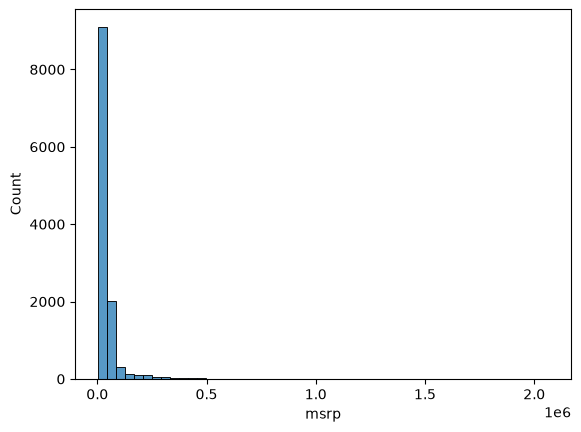

In [14]:
sns.histplot(df.msrp, bins=50)

The 1e6 on the x axis is scientific notation: 10 to the power of 6, that is, one million. 

And what we see is that a lot of prices are pretty cheap — most of the cars are concentrated on the left. 

Then there are very few cars that are super expensive: maybe one car costs 2 million, one costs 1.5 million, and a few cost around a million. 

There are not so many of them, but they have huge values.


This kind of distribution is called a *long-tail distribution*: most of the data sits in one place, and a shallow tail stretches far to the right. 

Long-tail distributions are very common for prices: most things are cheap because that's what the general public can afford, 

but there are a few super-expensive items for the few people who can buy them.

To see the shape better, we zoom in on prices below 100,000:

<Axes: xlabel='msrp', ylabel='Count'>

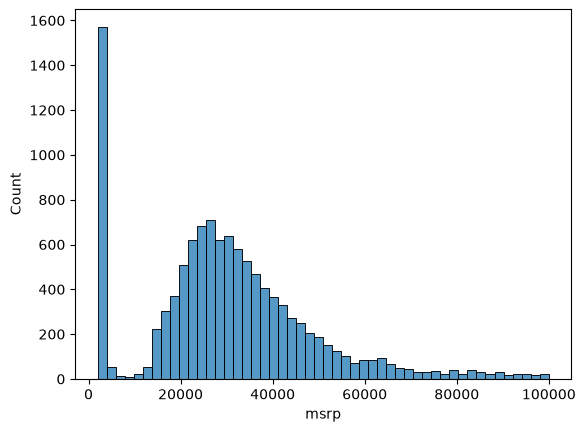

In [15]:
sns.histplot(df.msrp[df.msrp < 100000], bins=50)

This is the left part of the previous histogram, and it is much easier to read. 

There is a strange peak of cars that cost 1,000 — probably the minimal price possible to put on the platform, 

which is why a bunch of cars cost exactly that. T

hen the number of cars slowly grows up to around 25,000 — about 700 cars cost that much —

and after that it goes down as the price grows. 

Except for that peak at 1,000, this is a pretty reasonable distribution to expect for prices.

## Removing the long tail with a logarithm

While this distribution is not unexpected, it is not really good for machine learning: 

the long tail will confuse the model and screw things up. 
    
We want to get rid of it, and the usual trick is to apply the logarithm to the price.


The logarithm compresses large values. 
    
For large numbers, the value of the logarithm is not that large: going from 10 to 1,000 is a big jump, 

but the increase between their logarithms is not that high. 
    
So the logarithm takes very high values and makes them lower.


There is one problem with the plain logarithm: the logarithm of zero doesn't exist. 

If there is a zero in the data, numpy complains — it returns negative infinity and prints a warning:

In [16]:
import numpy as np
np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

RuntimeWarning: divide by zero encountered in log
array([-inf, 0., 2.30258509, 6.90775528, 11.51292546])

In our case prices are always 1,000 or more, so this can't happen. 

Still, it's pretty common to add one to all values before taking the logarithm, just to be safe. 

NumPy has a shortcut for exactly this: log1p, where "1p" stands for "plus one". It adds one to every value and then takes the logarithm:

In [17]:
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

Let's apply it to the prices and call the result price_logs:

In [18]:
price_logs = np.log1p(df.msrp)

Now we can plot the histogram of the logged prices:

<Axes: xlabel='msrp', ylabel='Count'>

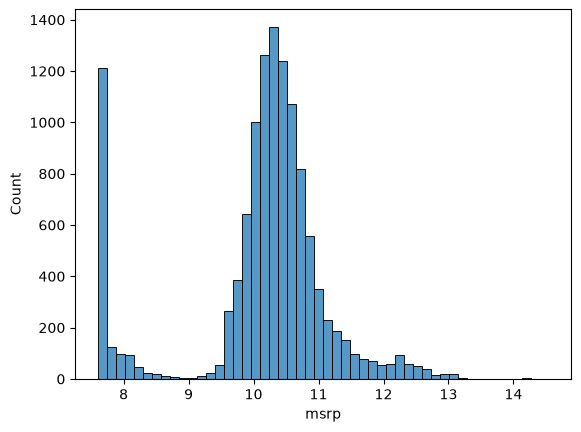

In [19]:
sns.histplot(price_logs, bins=50)

The tail is gone. All the large prices collapsed into a small area on the right, and the cars for usual consumers are still concentrated around the center. 

The shape now resembles a bell curve: a clear center of the distribution that goes down on both the left and the right side. 

This is called a normal distribution. (We still have that weird peak at 1,000, but apart from it, it looks close to normal.)


This situation is ideal for models: models do much better when the target variable looks like a normal distribution than with long-tail ones. 

That is why we typically want to get rid of long tails, and applying the logarithm to the price, like we just did, is one way of doing it.

## Missing values

One more thing before we finish: missing values. 

Some values in the dataset were not recorded. 

When pandas doesn't have a value, it shows it as NaN — not a number. 

We saw this when looking at the data: some cars have NaN in the number of doors column.


To count how many missing values there are, we use *isnull()*: for every cell it says whether the value in this cell is missing or not. 

In this form it is not super useful, so we follow it with *sum()*, 

which sums across every column and tells us the number of missing values in each:


In [20]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

For quite a few cars we don't know the fuel type, the market category, the horsepower or the number of cylinders. 

We need to keep this in mind: before training the model, we will need to do something with these missing values.

## To summarize: 

we looked at the different values in every column, 
then looked at the distribution of the price, 
saw that it has a long tail and removed its effect with a logarithm transformation,
and finally checked the missing values. 

In the next lesson we set up the validation framework, because before training a model we need to make sure we can validate it — see setting up the validation framework.

## Notes
Pandas attributes and methods:

* df[col].unique() -> return a list of unique values in the series
* df[col].nunique() -> return the number of unique values in the series
* df.isnull().sum() -> return the number of null values in the dataframe

**Matplotlib and seaborn methods**:

* %matplotlib inline -> assure that plots are displayed in jupyter notebook's cells
* sns.histplot() -> show the histogram of a series.

**Numpy methods**:

* np.log1p() -> apply log transformation to a variable, after adding one to each input value.

Long-tail distributions usually confuse the ML models, so the recommendation is to transform the target variable distribution to a normal one whenever possible.

# Setting up the validation framework

The dataset is cleaned and explored, so now we set up the validation framework: 

we split the data into train, validation and test parts, and prepare the target variable for each part. 

We do it manually, with plain pandas and NumPy.

## Train, validation and test


### Calculating the sizes of the parts

We will do a 60/20/20 split, so we first need to calculate how many records 20% actually is. 

Our dataframe has almost 12,000 records, so 20% of that is approximately 2,400. 

We want a whole number of records, not a fraction like 2382.8, so we cut the fraction off with int()

In [21]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

Ideally we would write n_train = int(n * 0.6) as well, but because of rounding, 

the three parts may stop adding up to n - and we would accidentally leave a few records out. 

So instead, we take validation and test out first, and whatever remains goes to training.

### Taking a part of the dataframe with iloc

Now we know the sizes, and we need to take a part of the dataframe of that size. 

For that we use iloc, which we saw in the introduction to pandas. 

We usually give it a list of indices, but it also accepts ranges. To get the first ten records:

In [23]:
#This is from the beginning till 10, not inclusive, so records 0 to 9. 
df.iloc[:10]

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
5,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,31200
6,bmw,1_series,2012,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,26,17,3916,44100
7,bmw,1_series,2012,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,39300
8,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,36900
9,bmw,1_series,2013,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,27,18,3916,37200


So the simplest thing we can do is cut the dataframe sequentially:

In [25]:
df_val = df.iloc[:n_val]
df_test = df.iloc[n_val:n_val+n_test]
df_train = df.iloc[n_val+n_test:]

In [26]:
df_val

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2377,porsche,cayenne,2016,premium_unleaded_(required),570.0,8.0,automatic,all_wheel_drive,4.0,"crossover,luxury,high-performance",midsize,4dr_suv,21,14,1715,157300
2378,porsche,cayenne,2016,diesel,240.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury,diesel",midsize,4dr_suv,29,20,1715,62300
2379,porsche,cayenne,2017,premium_unleaded_(required),520.0,8.0,automatic,all_wheel_drive,4.0,"crossover,luxury,performance",midsize,4dr_suv,21,14,1715,116500
2380,porsche,cayenne,2017,premium_unleaded_(required),300.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,24,18,1715,59600


There is a problem here, though: the split is sequential. In our dataset the cars are ordered by make, so validation now contains all the BMWs at the beginning and all the Porsches at the end, and there are no BMWs in train at all:

We see that there is some order in this dataset, and we need to break it. In general it is always a good idea to shuffle the data: if there is some accidental order in it, we want to make sure it does not affect the split.

### Shuffling the records

Here is the idea. In iloc we can pass an arbitrary sequence of numbers, 

and it will return the rows in that order. 

So we can take the numbers from 0 to n-1, reshuffle them, 

and then take the first 20% of the shuffled numbers for validation, 

the next 20% for test, and the rest for train:

To generate the sequence of numbers we use np.arange from NumPy, and to shuffle it we use np.random.shuffle:

In [30]:
#np.arange() -> return an array of numbers, in this case base of the size of n
idx = np.arange(n)
np.random.shuffle(idx) #np.random.shuffle() -> return a shuffled array
idx

array([ 6399, 11055, 10373, ...,  3098,   815,  6732], shape=(11914,))

Now we index the dataframe with the shuffled numbers instead of the sequential ranges:

In [28]:
#iloc uses the logical index 1,2...,n
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [29]:
df_train.head(5) #head shows that the index numbers are not secuential.

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
3046,honda,cr-v,2014,regular_unleaded,185.0,4.0,automatic,front_wheel_drive,4.0,crossover,compact,4dr_suv,31,23,2202,27870
6781,acura,mdx,2016,premium_unleaded_(recommended),290.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,26,19,204,57230
4892,volkswagen,fox,1993,regular_unleaded,81.0,4.0,manual,front_wheel_drive,4.0,NaN,compact,sedan,30,22,873,2000
5920,acura,integra,1999,regular_unleaded,140.0,4.0,manual,front_wheel_drive,2.0,"hatchback,luxury",compact,2dr_hatchback,29,22,204,2912
3906,honda,element,2010,regular_unleaded,166.0,4.0,automatic,all_wheel_drive,4.0,crossover,compact,4dr_suv,24,19,2202,21775


We take the first n_train numbers for train, the next n_val numbers for validation, and everything that is left for test:

There is one more problem with this code: when you run it on your computer, 
you will get different records - your first car will not be a Porsche or a GMC, 
but something else. To make the results reproducible, we set a random seed before shuffling. 

We talked about it in the introduction to NumPy:

In [31]:
np.random.seed(2) #seed is used to make results reproducible, random will get the same numbers

idx = np.arange(n)
np.random.shuffle(idx)

In [33]:
#iloc uses the logical index 1,2...,n
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [34]:
df_train.head(5)

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
2735,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
6720,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
5878,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
11190,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4554,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260


With the seed set to 2, the first record in train is a Chevrolet,

and if you have the same version of NumPy, you will get exactly the same subset on your computer.

### Resetting the index

Let's check the lengths of the three dataframes:

In [35]:
len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

Looking at df_train, we see that the index now contains the original row numbers

- 2735, 6720 and so on, in random order.

Sometimes it is inconvenient: we don't really need to know what the original index of each record was. 

So we reset the index and reassign the result back to the dataframe. 

We pass drop=True because we don't need the old index as a column:

In [36]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [37]:
df_train #notice chevrolet now is at position 0

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,chevrolet,cobalt,2008,regular_unleaded,148.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,33,24,1385,14410
1,toyota,matrix,2012,regular_unleaded,132.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,32,25,2031,19685
2,subaru,impreza,2016,regular_unleaded,148.0,4.0,automatic,all_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,28,640,19795
3,volkswagen,vanagon,1991,regular_unleaded,90.0,4.0,manual,rear_wheel_drive,3.0,NaN,large,passenger_minivan,18,16,873,2000
4,ford,f-150,2017,flex-fuel_(unleaded/e85),385.0,8.0,automatic,four_wheel_drive,4.0,flex_fuel,large,crew_cab_pickup,21,15,5657,56260
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,bmw,4_series,2015,premium_unleaded_(required),300.0,6.0,automatic,rear_wheel_drive,2.0,"luxury,performance",midsize,convertible,31,20,3916,54900
7146,volkswagen,beetle,2015,premium_unleaded_(recommended),210.0,4.0,automated_manual,front_wheel_drive,2.0,"hatchback,performance",compact,2dr_hatchback,30,24,873,29215
7147,gmc,sierra_1500,2015,flex-fuel_(unleaded/e85),285.0,6.0,automatic,four_wheel_drive,4.0,flex_fuel,large,extended_cab_pickup,22,17,549,34675
7148,rolls-royce,ghost,2014,premium_unleaded_(required),563.0,12.0,automatic,rear_wheel_drive,4.0,"exotic,luxury,performance",large,sedan,21,13,86,303300


Now the index goes from 0 to 7149 again.

### Preparing y and removing msrp

The dataframes will be used to make the feature matrix X. 

The target y comes from the msrp column, 

and we already know that we need to apply the log1p transformation to it

because of the long tail in its distribution. 

Instead of keeping a pandas series, we immediately take its values with .values to get a NumPy array 

- we don't need the indexes and other pandas things for y:


In [38]:
#saving the prices column in variables
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

The last thing we need to do is remove msrp from the dataframes, for which we use the del operator:

In [39]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

We delete it because we might accidentally use it. 

If the price gets into the features, we will use the price to predict the price

and of course the model will be perfect. 

# Linear regression

In this lesson we look at linear regression, the model we use for solving regression problems 

- problems where we predict a number, like the price of a car.
-
- We derive the formula, implement it in Python for one car, and see what the prediction is made of.

## The formula for one car

Linear regression is a model for solving regression problems. 

Remember from the introduction: 

there is regression, there is classification and there is ranking. 

Regression means predicting numbers, and the output of this model is a number 

- in our case, the price of a car.

You probably remember this formula from the introduction lesson:

g(X) ≈ y

Here g is our model, X is the feature matrix and y is our target - the price. 

The model g will be linear regression.

Before we go to the matrix form, let's simplify and look at one observation instead of the entire feature matrix. 

One observation is one car, and this is its price:

A car can be a row in our feature matrix, 
so we can think of it as a vector with n elements: 

the first feature is xi1, then xi2, and so on until xin. 

We want a function that takes all these features and produces something close to the price:

g(xi) ≈ yi
